In [273]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import mannwhitneyu
from sklearn.metrics import mean_absolute_error,mean_absolute_percentage_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [ ]:


df = pd.read_csv("../data/raw/ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv")

df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


In [5]:
df.tail()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
242139,2026-09,YISHUN,EXECUTIVE,828,YISHUN ST 81,10 TO 12,146.0,Maisonette,1988,60 years 05 months,1010000.0
242140,2026-05,YISHUN,MULTI-GENERATION,666,YISHUN AVE 4,04 TO 06,164.0,Multi Generation,1987,60 years 08 months,1120000.0
242141,2026-09,YISHUN,MULTI-GENERATION,666,YISHUN AVE 4,10 TO 12,151.0,Multi Generation,1987,60 years 04 months,1212000.0
242142,2026-07,YISHUN,MULTI-GENERATION,605,YISHUN ST 61,07 TO 09,163.0,Multi Generation,1988,60 years 07 months,1190000.0
242143,2026-10,YISHUN,MULTI-GENERATION,633,YISHUN ST 61,10 TO 12,171.0,Multi Generation,1987,60 years 03 months,1178000.0


In [4]:
df.shape

(242144, 11)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 242144 entries, 0 to 242143
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                242144 non-null  str    
 1   town                 242144 non-null  str    
 2   flat_type            242144 non-null  str    
 3   block                242144 non-null  str    
 4   street_name          242144 non-null  str    
 5   storey_range         242144 non-null  str    
 6   floor_area_sqm       242144 non-null  float64
 7   flat_model           242144 non-null  str    
 8   lease_commence_date  242144 non-null  int64  
 9   remaining_lease      242144 non-null  str    
 10  resale_price         242144 non-null  float64
dtypes: float64(2), int64(1), str(8)
memory usage: 20.3 MB


In [2]:
df. describe()

,floor_area_sqm,lease_commence_date,resale_price
count,242144.000000,242144.000000,2.421440e+05
mean,96.712421,1996.629241,5.361206e+05
std,24.024253,14.398896,1.932048e+05
min,31.000000,1966.000000,1.400000e+05
25%,81.000000,1985.000000,3.920000e+05
50%,93.000000,1997.000000,5.050000e+05
75%,112.000000,2012.000000,6.450000e+05
max,366.700000,2023.000000,1.728000e+06


In [19]:
duplikat = df[df.duplicated(keep=False)]
duplikat.sort_values(by=list(df.columns))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
224,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.0,Improved,1975,57 years,470000.0
243,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.0,Improved,1975,57 years,470000.0
304,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.0,Improved,1979,61 years 02 months,470000.0
305,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.0,Improved,1979,61 years 02 months,470000.0
505,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.0,Model A,1998,80 years 09 months,470000.0
...,...,...,...,...,...,...,...,...,...,...,...
231968,2026-06,PASIR RIS,4 ROOM,530A,PASIR RIS DR 1,07 TO 09,86.0,DBSS,2015,88 years,828000.0
226924,2026-08,CHOA CHU KANG,3 ROOM,10,TECK WHYE AVE,04 TO 06,67.0,New Generation,1978,50 years 09 months,330000.0
226925,2026-08,CHOA CHU KANG,3 ROOM,10,TECK WHYE AVE,04 TO 06,67.0,New Generation,1978,50 years 09 months,330000.0
230362,2026-08,JURONG WEST,4 ROOM,541,JURONG WEST AVE 1,04 TO 06,103.0,Model A,1984,57 years 04 months,500000.0


In [22]:
df.duplicated().sum()

np.int64(318)

In [27]:
df['flat_model'].value_counts()

flat_model
Model A                   87380
Improved                  59087
New Generation            29319
Premium Apartment         26458
Simplified                 9234
Apartment                  8653
Maisonette                 6619
Standard                   6413
DBSS                       3831
Model A2                   2713
2-room                      517
Model A-Maisonette          420
Adjoined flat               416
Type S1                     393
Type S2                     199
Premium Apartment Loft      139
Terrace                     123
Multi Generation             91
3Gen                         84
Improved-Maisonette          33
Premium Maisonette           22
Name: count, dtype: int64

In [28]:
df['flat_type'].value_counts()

flat_type
4 ROOM              102927
5 ROOM               59242
3 ROOM               57446
EXECUTIVE            17254
2 ROOM                5095
MULTI-GENERATION        91
1 ROOM                  89
Name: count, dtype: int64

In [29]:
df['storey_range'].value_counts()

storey_range
04 TO 06    55536
07 TO 09    50740
10 TO 12    45213
01 TO 03    42455
13 TO 15    23395
16 TO 18    10970
19 TO 21     4751
22 TO 24     3317
25 TO 27     2066
28 TO 30     1363
31 TO 33      745
34 TO 36      655
37 TO 39      532
40 TO 42      259
43 TO 45       76
46 TO 48       52
49 TO 51       19
Name: count, dtype: int64

In [30]:
pd.crosstab(df['flat_model'],df['flat_type'])

flat_type,1 ROOM,2 ROOM,3 ROOM,4 ROOM,5 ROOM,EXECUTIVE,MULTI-GENERATION
flat_model,,,,,,,
2-room,0,517,0,0,0,0,0
3Gen,0,0,0,0,84,0,0
Adjoined flat,0,0,0,37,238,141,0
Apartment,0,0,0,0,0,8653,0
DBSS,0,3,530,1592,1706,0,0
Improved,89,642,13821,2597,41938,0,0
Improved-Maisonette,0,0,0,0,33,0,0
Maisonette,0,0,0,0,0,6619,0
Model A,0,3166,17167,64029,3018,0,0






# Data Cleaning & Feature Enginering

In [40]:
df['month_date'] = pd.to_datetime(df['month'])

year = df['remaining_lease'].str.extract(r'(\d+)\s*year')[0].fillna(0).astype(float)
month = df['remaining_lease'].str.extract(r'(\d+)\s*month')[0].fillna(0).astype(float)

# print(year,month)

df['remaining_lease_year'] = year + (month/12)

df['is_duplicate']= df.duplicated(keep=False)

df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,month_date,remaining_lease_year,is_duplicate
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0,2017-01-01,61.333333,False
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0,2017-01-01,60.583333,False
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0,2017-01-01,62.416667,False
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0,2017-01-01,62.083333,False
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0,2017-01-01,62.416667,False


In [41]:
df.tail()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,month_date,remaining_lease_year,is_duplicate
242139,2026-09,YISHUN,EXECUTIVE,828,YISHUN ST 81,10 TO 12,146.0,Maisonette,1988,60 years 05 months,1010000.0,2026-09-01,60.416667,False
242140,2026-05,YISHUN,MULTI-GENERATION,666,YISHUN AVE 4,04 TO 06,164.0,Multi Generation,1987,60 years 08 months,1120000.0,2026-05-01,60.666667,False
242141,2026-09,YISHUN,MULTI-GENERATION,666,YISHUN AVE 4,10 TO 12,151.0,Multi Generation,1987,60 years 04 months,1212000.0,2026-09-01,60.333333,False
242142,2026-07,YISHUN,MULTI-GENERATION,605,YISHUN ST 61,07 TO 09,163.0,Multi Generation,1988,60 years 07 months,1190000.0,2026-07-01,60.583333,False
242143,2026-10,YISHUN,MULTI-GENERATION,633,YISHUN ST 61,10 TO 12,171.0,Multi Generation,1987,60 years 03 months,1178000.0,2026-10-01,60.250000,False


In [42]:
df.dtypes

month                              str
town                               str
flat_type                          str
block                              str
street_name                        str
storey_range                       str
floor_area_sqm                 float64
flat_model                         str
lease_commence_date              int64
remaining_lease                    str
resale_price                   float64
month_date              datetime64[us]
remaining_lease_year           float64
is_duplicate                      bool
dtype: object

In [45]:
df['storey_range'].value_counts().sort_values(ascending=True)

storey_range
49 TO 51       19
46 TO 48       52
43 TO 45       76
40 TO 42      259
37 TO 39      532
34 TO 36      655
31 TO 33      745
28 TO 30     1363
25 TO 27     2066
22 TO 24     3317
19 TO 21     4751
16 TO 18    10970
13 TO 15    23395
01 TO 03    42455
10 TO 12    45213
07 TO 09    50740
04 TO 06    55536
Name: count, dtype: int64

In [64]:
df['price_per_sqm'] = df['resale_price']/ df['floor_area_sqm']

df[['town','flat_type','floor_area_sqm','resale_price','price_per_sqm','remaining_lease_year','month']].sort_values(by='price_per_sqm').head()


,town,flat_type,floor_area_sqm,resale_price,price_per_sqm,remaining_lease_year,month
67560,TOA PAYOH,3 ROOM,67.0,140000.0,2089.552239,49.916667,2020-02
50187,TOA PAYOH,3 ROOM,77.0,170000.0,2207.792208,49.666667,2019-05
163898,TAMPINES,3 ROOM,67.0,150000.0,2238.805970,91.250000,2023-08
52354,YISHUN,4 ROOM,104.0,240000.0,2307.692308,68.083333,2019-06
87119,TAMPINES,4 ROOM,107.0,250000.0,2336.448598,74.250000,2020-12


In [65]:
df[['town','flat_type','floor_area_sqm','resale_price','price_per_sqm','remaining_lease_year','month']].sort_values(by='price_per_sqm').tail()

,town,flat_type,floor_area_sqm,resale_price,price_per_sqm,remaining_lease_year,month
226864,CENTRAL AREA,5 ROOM,107.0,1720000.0,16074.766355,83.333333,2026-09
226810,CENTRAL AREA,4 ROOM,96.0,1550000.0,16145.833333,83.666667,2026-05
202725,CENTRAL AREA,4 ROOM,94.0,1518000.0,16148.936170,85.166667,2025-03
234471,QUEENSTOWN,5 ROOM,99.0,1600000.0,16161.616162,88.583333,2026-09
226822,CENTRAL AREA,4 ROOM,95.0,1588000.0,16715.789474,83.333333,2026-10


# EDA

1. Numeric

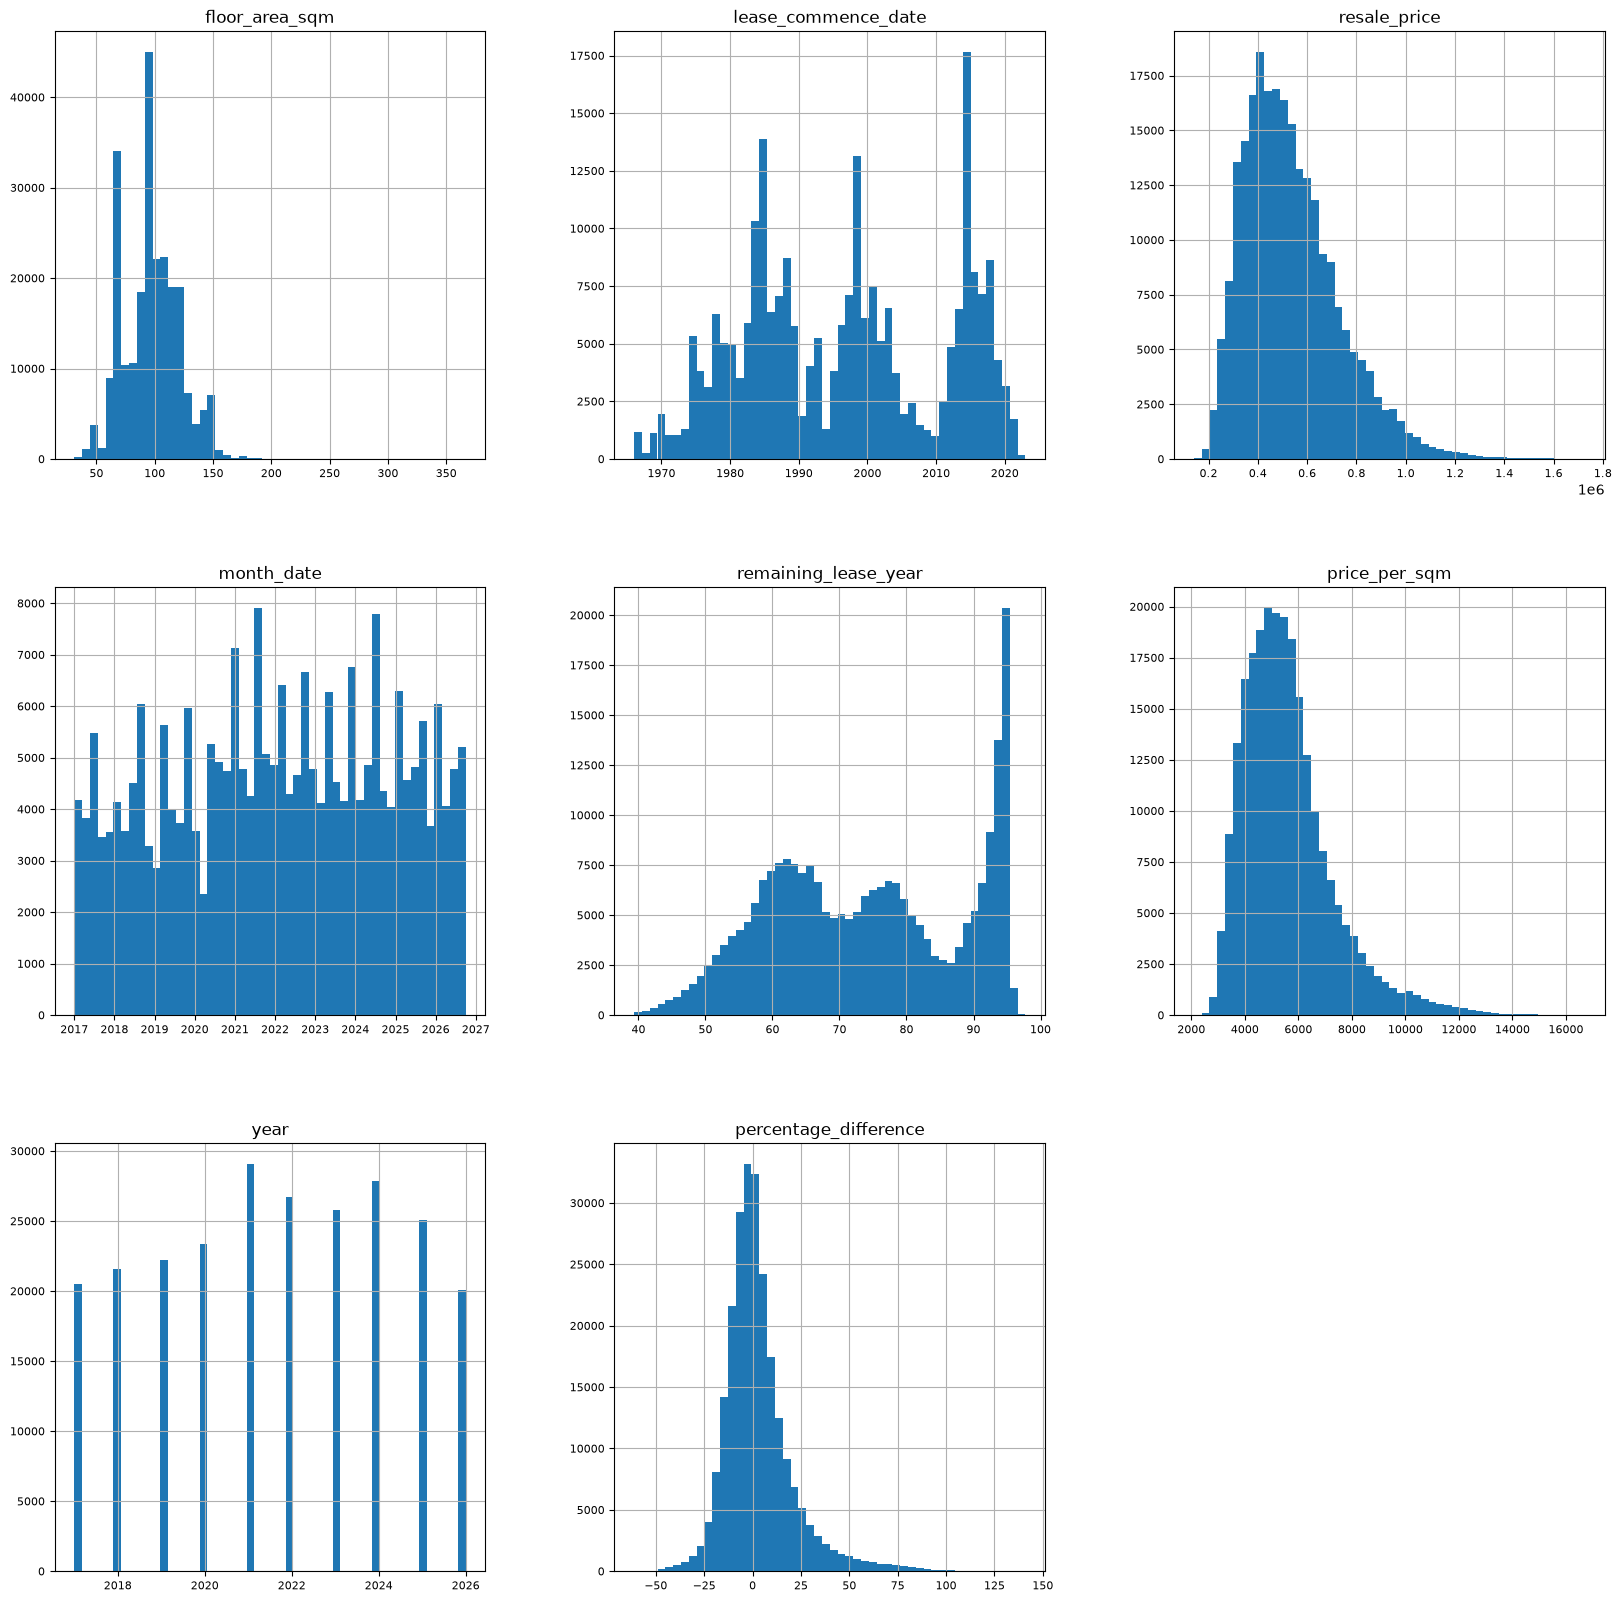

In [120]:
fig_ = df.hist(
    figsize=(20,20),
    bins=50,
    xlabelsize=8,
    ylabelsize=8
    )

In [121]:
df[(df['town']=='YISHUN')&(df['flat_type']=='4 ROOM')&(df['month_date'].dt.year == 2019)]['price_per_sqm'].median()

np.float64(3763.440860215054)

In [122]:
df[(df['town']=='TAMPINES')&(df['flat_type']=='4 ROOM')&(df['month_date'].dt.year == 2020)]['price_per_sqm'].median()

np.float64(4275.345407020164)

In [95]:
df['year'] = df['month_date'].dt.year
median = df.groupby(['town','flat_type','year'])['price_per_sqm'].transform('median')

percent = ((df['price_per_sqm'] - median) / median)*100


df['percentage_difference'] = percent
percent.describe()

count    242144.000000
mean          2.969904
std          17.923595
min         -61.291672
25%          -7.570423
50%           0.000000
75%           9.523810
max         140.989011
Name: price_per_sqm, dtype: float64

In [96]:
df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,month_date,remaining_lease_year,is_duplicate,price_per_sqm,year,percentage_difference
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0,2017-01-01,61.333333,False,5272.727273,2017,0.000000
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0,2017-01-01,60.583333,False,3731.343284,2017,-15.143907
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0,2017-01-01,62.416667,False,3910.447761,2017,-11.070814
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0,2017-01-01,62.083333,False,3897.058824,2017,-11.375298
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0,2017-01-01,62.416667,False,3955.223881,2017,-10.052541


In [100]:
df[['town','flat_type','floor_area_sqm','resale_price','price_per_sqm','remaining_lease_year','month','percentage_difference']].sort_values(by='price_per_sqm').head(10)


,town,flat_type,floor_area_sqm,resale_price,price_per_sqm,remaining_lease_year,month,percentage_difference
67560,TOA PAYOH,3 ROOM,67.0,140000.0,2089.552239,49.916667,2020-02,-47.064677
50187,TOA PAYOH,3 ROOM,77.0,170000.0,2207.792208,49.666667,2019-05,-42.257742
163898,TAMPINES,3 ROOM,67.0,150000.0,2238.805970,91.250000,2023-08,-61.291672
52354,YISHUN,4 ROOM,104.0,240000.0,2307.692308,68.083333,2019-06,-38.681319
87119,TAMPINES,4 ROOM,107.0,250000.0,2336.448598,74.250000,2020-12,-45.350647
58066,WOODLANDS,5 ROOM,115.0,270000.0,2347.826087,57.000000,2019-09,-29.862411
64018,WOODLANDS,5 ROOM,121.0,285000.0,2355.371901,57.333333,2019-12,-29.636991
65939,WOODLANDS,5 ROOM,123.0,290000.0,2357.723577,55.166667,2020-01,-32.636469
70123,WOODLANDS,5 ROOM,118.0,280000.0,2372.881356,56.500000,2020-04,-32.203390
70122,WOODLANDS,5 ROOM,120.0,285000.0,2375.000000,54.833333,2020-04,-32.142857


In [101]:
df[['town','flat_type','floor_area_sqm','resale_price','price_per_sqm','remaining_lease_year','month','percentage_difference']].sort_values(by='price_per_sqm').tail(10)

,town,flat_type,floor_area_sqm,resale_price,price_per_sqm,remaining_lease_year,month,percentage_difference
226792,CENTRAL AREA,4 ROOM,95.0,1500000.0,15789.473684,84.083333,2026-01,58.085201
226815,CENTRAL AREA,4 ROOM,93.0,1475000.0,15860.215054,83.500000,2026-08,58.793468
226863,CENTRAL AREA,5 ROOM,107.0,1701000.0,15897.196262,83.416667,2026-09,14.932432
202754,CENTRAL AREA,4 ROOM,93.0,1480000.0,15913.978495,84.333333,2025-10,21.413377
202752,CENTRAL AREA,4 ROOM,93.0,1490000.0,16021.505376,84.333333,2025-09,22.233737
226864,CENTRAL AREA,5 ROOM,107.0,1720000.0,16074.766355,83.333333,2026-09,16.216216
226810,CENTRAL AREA,4 ROOM,96.0,1550000.0,16145.833333,83.666667,2026-05,61.653096
202725,CENTRAL AREA,4 ROOM,94.0,1518000.0,16148.936170,85.166667,2025-03,23.205952
234471,QUEENSTOWN,5 ROOM,99.0,1600000.0,16161.616162,88.583333,2026-09,55.277360
226822,CENTRAL AREA,4 ROOM,95.0,1588000.0,16715.789474,83.333333,2026-10,67.359533


In [108]:
df['is_outlier'] = df['percentage_difference'].abs() > 40

df[df['is_outlier'] == True]

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,month_date,remaining_lease_year,is_duplicate,price_per_sqm,year,percentage_difference,is_outlier
46,2017-01,ANG MO KIO,4 ROOM,588C,ANG MO KIO ST 52,13 TO 15,90.0,DBSS,2011,93 years 08 months,688000.0,2017-01-01,93.666667,False,7644.444444,2017,54.517007,True
47,2017-01,ANG MO KIO,4 ROOM,588D,ANG MO KIO ST 52,19 TO 21,91.0,DBSS,2011,93 years 07 months,730000.0,2017-01-01,93.583333,False,8021.978022,2017,62.148086,True
48,2017-01,ANG MO KIO,4 ROOM,588D,ANG MO KIO ST 52,22 TO 24,91.0,DBSS,2011,93 years 07 months,756000.0,2017-01-01,93.583333,False,8307.692308,2017,67.923224,True
112,2017-01,BEDOK,4 ROOM,220B,BEDOK CTRL,10 TO 12,97.0,Model A,2010,92 years 04 months,671000.0,2017-01-01,92.333333,False,6917.525773,2017,53.107904,True
121,2017-01,BEDOK,5 ROOM,219C,BEDOK CTRL,13 TO 15,112.0,Improved,2010,92 years 04 months,795000.0,2017-01-01,92.333333,False,7098.214286,2017,52.010176,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241259,2026-01,YISHUN,4 ROOM,348C,YISHUN AVE 11,07 TO 09,92.0,DBSS,2013,86 years 09 months,772888.0,2026-01-01,86.750000,False,8400.956522,2026,42.561686,True
241266,2026-02,YISHUN,4 ROOM,348A,YISHUN AVE 11,07 TO 09,92.0,DBSS,2013,86 years 08 months,775000.0,2026-02-01,86.666667,False,8423.913043,2026,42.951252,True
241282,2026-06,YISHUN,4 ROOM,348D,YISHUN AVE 11,13 TO 15,92.0,DBSS,2013,86 years 05 months,788888.0,2026-06-01,86.416667,False,8574.869565,2026,45.512938,True
241283,2026-06,YISHUN,4 ROOM,348A,YISHUN AVE 11,10 TO 12,92.0,DBSS,2013,86 years 04 months,823888.0,2026-06-01,86.333333,False,8955.304348,2026,51.968801,True


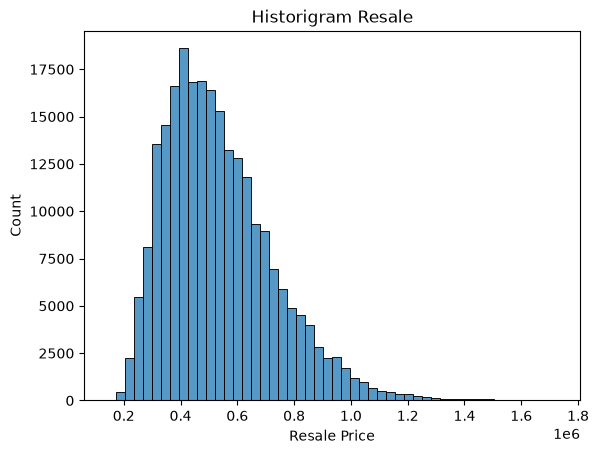

In [103]:
plt.Figure(figsize=(10,12))
sns.histplot(data=df , x='resale_price',bins=50)
plt.title("Historigram Resale")
plt.xlabel("Resale Price")
plt.ylabel("Count")
plt.show()

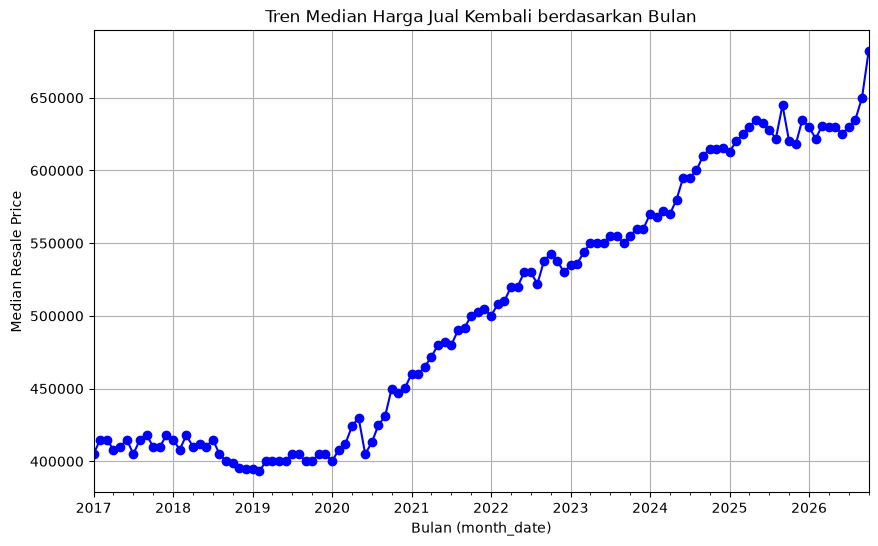

In [194]:
trend_price_time = df.groupby('month_date')['resale_price'].median()

plt.figure(figsize=(10,6))
trend_price_time.plot(kind = 'line', marker='o', color='b', grid=True)
plt.title('Tren Median Harga Jual Kembali berdasarkan Bulan')
plt.xlabel('Bulan (month_date)')
plt.ylabel('Median Resale Price')
plt.show()


In [118]:
df.groupby('month_date').size().tail()

month_date
2026-06-01    2125
2026-07-01    2648
2026-08-01    2519
2026-09-01    2246
2026-10-01     438
dtype: int64

2. Category

/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_93646/3469583157.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=categ_df, y=col, order=order, ax=axes[i], palette="viridis")
/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_93646/3469583157.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=categ_df, y=col, order=order, ax=axes[i], palette="viridis")
/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_93646/3469583157.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=categ_df, y=col, 

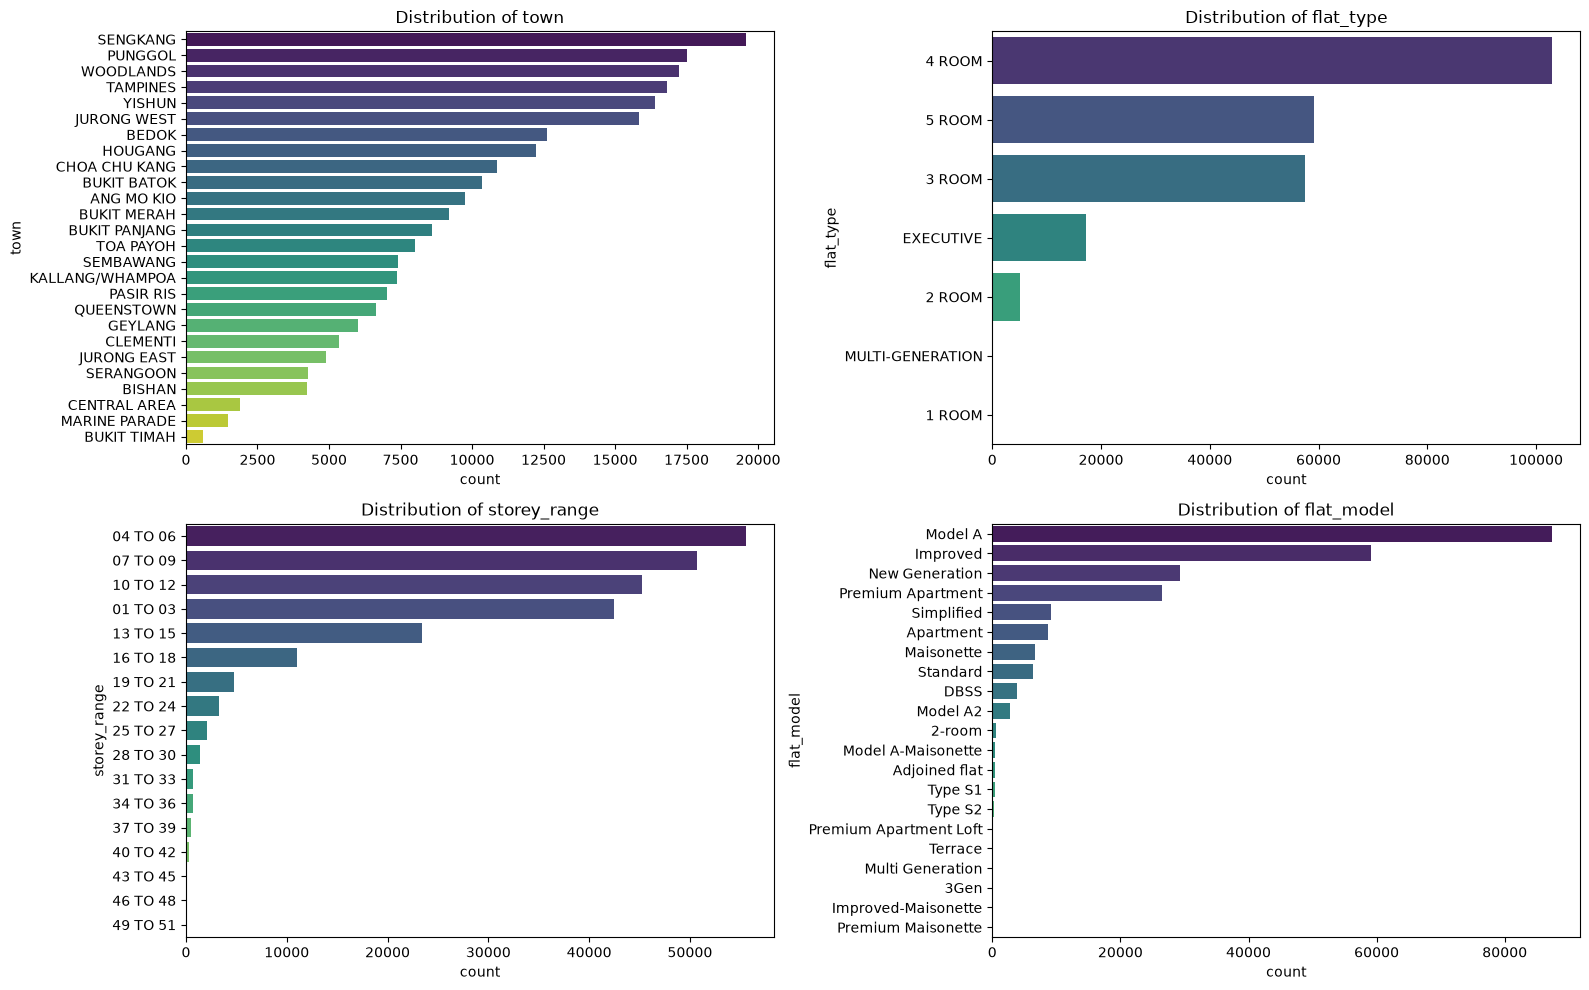

In [139]:

# Filter kolom kategorikal dengan nunique ideal (< 20)
valid_cols = [col for col in categ_df.columns if categ_df[col].nunique() < 30]

# Tentukan jumlah baris grid
ncols = 2
nrows = (len(valid_cols) + 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, nrows * 5))
axes = axes.flatten()

for i, col in enumerate(valid_cols):
    # Plot horizontal agar label mudah dibaca
    order = categ_df[col].value_counts().index
    sns.countplot(data=categ_df, y=col, order=order, ax=axes[i], palette="viridis")
    axes[i].set_title(f'Distribution of {col}')

# Sembunyikan subplot sisa jika ada grid kosong
for j in range(i + 1, len(axes)):
    axes[j].set_axis_off()

plt.tight_layout()
plt.show()

<Axes: ylabel='town'>

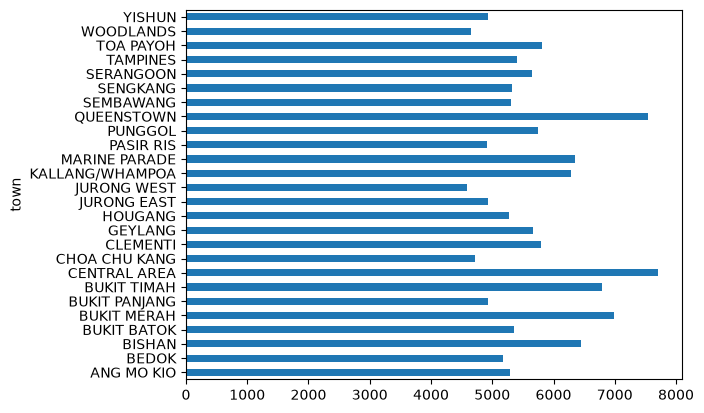

In [ ]:
median_by_town = df.groupby('town')['price_per_sqm'].median()


In [ ]:
median_by_town.sort_values()


town
JURONG WEST        4594.594595
WOODLANDS          4646.464646
CHOA CHU KANG      4722.222222
PASIR RIS          4919.677419
YISHUN             4925.373134
JURONG EAST        4930.693069
BUKIT PANJANG      4935.483871
BEDOK              5178.571429
HOUGANG            5267.175573
ANG MO KIO         5294.117647
SEMBAWANG          5311.111111
SENGKANG           5321.428571
BUKIT BATOK        5357.142857
TAMPINES           5403.225806
SERANGOON          5654.761905
GEYLANG            5670.329670
PUNGGOL            5752.212389
CLEMENTI           5802.149254
TOA PAYOH          5811.388311
KALLANG/WHAMPOA    6288.512241
MARINE PARADE      6346.153846
BISHAN             6442.307692
BUKIT TIMAH        6792.156120
BUKIT MERAH        6992.753623
QUEENSTOWN         7545.454545
CENTRAL AREA       7711.864407
Name: price_per_sqm, dtype: float64

<Axes: ylabel='town'>

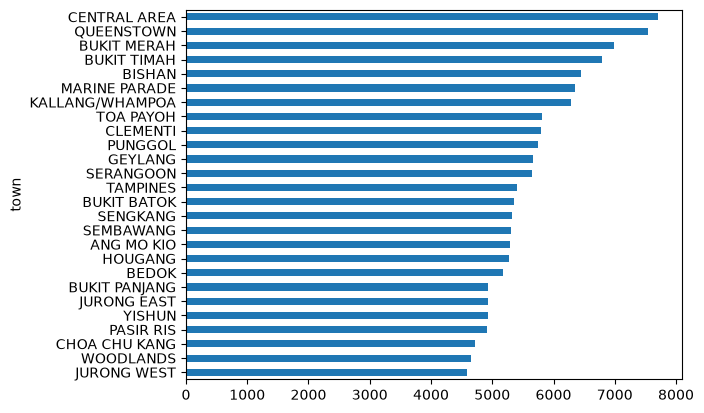

In [156]:
median_by_town.sort_values().plot.barh()

**Initial hypothesis vs evidence (sementara): H-A, "lokasi adalah faktor terbesar", didukung sebagian: lokasi jelas penting, tapi belum terbukti paling besar. Chart ini juga menggabungkan semua tahun dan tipe flat, dan belum ada uji statistik apakah selisih antar town signifikan. Kita kembali ke itu saat tahap hypothesis testing.**

In [141]:
median_by_town.max()

np.float64(7711.864406779661)

In [144]:
selisih = median_by_town.max() - median_by_town.min()

persen_selisih = (selisih / median_by_town.min()) * 100

print(f"{persen_selisih:.2f}%")

67.85%


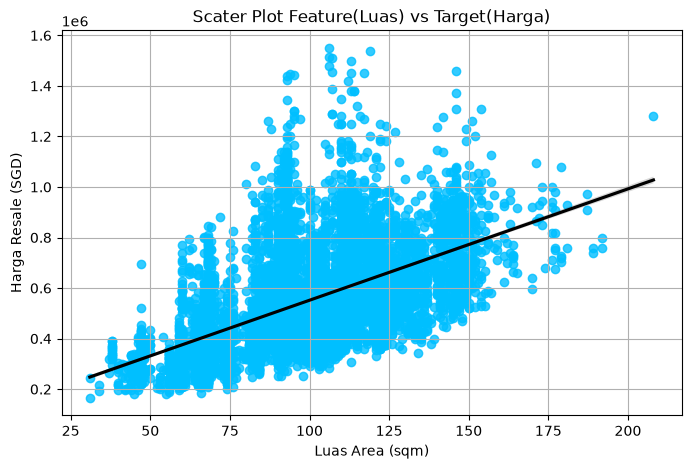

In [165]:
sampel=df.sample(10000,random_state=42)

plt.figure(figsize=(8,5))
sns.regplot(data=sampel, x='floor_area_sqm', y='resale_price',line_kws={"color": "black"},scatter_kws={"color": "deepskyblue"},)
plt.xlabel('Luas Area (sqm)')
plt.ylabel('Harga Resale (SGD)')
plt.title('Scater Plot Feature(Luas) vs Target(Harga)')
plt.grid(True)
plt.show()

**H-B ("hampir lurus") didukung sebagian. Arahnya lurus ke atas, tapi hubungannya sedang, bukan kuat.**

In [ ]:
df_2025 = df[(df['month_date'].dt.year == 2025)&(df['flat_type']=='4 ROOM')].copy()


bins = [40,50,60,70,80,90,100]
labels = ['40-50', '50-60', '60-70', '70-80', '80-90', '90+']
df_2025['lease_group'] = pd.cut(df_2025['remaining_lease_year'],labels=labels,bins=bins)

print(df_2025.value_counts().sort_index())

          month        town flat_type block       street_name storey_range  \
197534  2025-01  ANG MO KIO    4 ROOM   337  ANG MO KIO AVE 1     13 TO 15   
197535  2025-01  ANG MO KIO    4 ROOM  310C  ANG MO KIO AVE 1     10 TO 12   
197536  2025-01  ANG MO KIO    4 ROOM   337  ANG MO KIO AVE 1     10 TO 12   
197537  2025-02  ANG MO KIO    4 ROOM   226  ANG MO KIO AVE 1     07 TO 09   
197538  2025-02  ANG MO KIO    4 ROOM  310C  ANG MO KIO AVE 1     28 TO 30   
...         ...         ...       ...   ...               ...          ...   
221727  2025-10      YISHUN    4 ROOM   816      YISHUN ST 81     01 TO 03   
221728  2025-11      YISHUN    4 ROOM   868      YISHUN ST 81     10 TO 12   
221729  2025-11      YISHUN    4 ROOM   821      YISHUN ST 81     07 TO 09   
221730  2025-12      YISHUN    4 ROOM   852      YISHUN ST 81     07 TO 09   
221731  2025-12      YISHUN    4 ROOM   867      YISHUN ST 81     04 TO 06   

        floor_area_sqm      flat_model  lease_commence_date  \


<Axes: title={'center': 'Median Harga per sqm'}, xlabel='lease_group'>

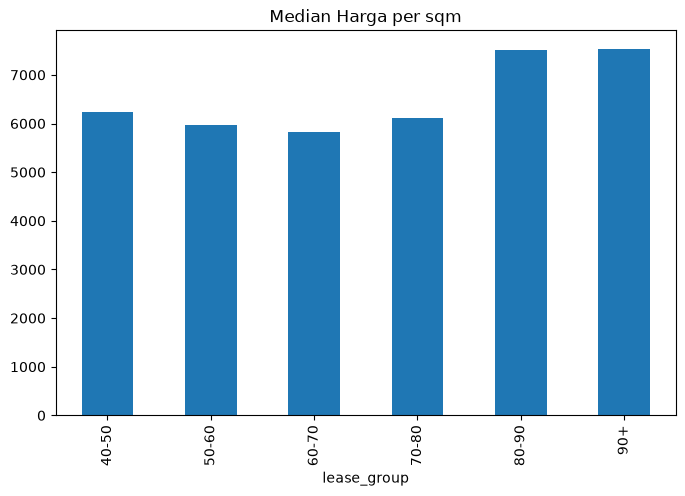

In [188]:
lease_median = df_2025.groupby('lease_group')['price_per_sqm'].median()

lease_median.plot(kind='bar', figsize=(8,5), title='Median Harga per sqm')

In [190]:
df_2025['lease_group'].value_counts()

lease_group
90+      2613
70-80    2400
80-90    2059
50-60    1798
60-70    1782
40-50     191
Name: count, dtype: int64

**Initial hypothesis vs evidence: H-C tidak didukung sebagai hubungan lurus. Lease memang berhubungan dengan harga, tapi polanya tidak sesederhana "makin pendek, makin murah".**

In [192]:
df_2025.groupby('lease_group')['town'].value_counts(normalize=True).groupby(level=0).head()

lease_group  town           
40-50        TOA PAYOH         0.21
             KALLANG/WHAMPOA   0.15
             MARINE PARADE     0.15
             BUKIT MERAH       0.12
             QUEENSTOWN        0.08
50-60        BEDOK             0.12
             TAMPINES          0.12
             YISHUN            0.10
             ANG MO KIO        0.10
             BUKIT BATOK       0.07
60-70        YISHUN            0.16
             TAMPINES          0.14
             PASIR RIS         0.10
             JURONG WEST       0.09
             CHOA CHU KANG     0.09
70-80        WOODLANDS         0.20
             SENGKANG          0.14
             JURONG WEST       0.08
             CHOA CHU KANG     0.08
             SEMBAWANG         0.07
80-90        PUNGGOL           0.23
             SENGKANG          0.19
             YISHUN            0.10
             QUEENSTOWN        0.06
             BUKIT PANJANG     0.06
90+          SEMBAWANG         0.13
             BUKIT BATOK       0.11

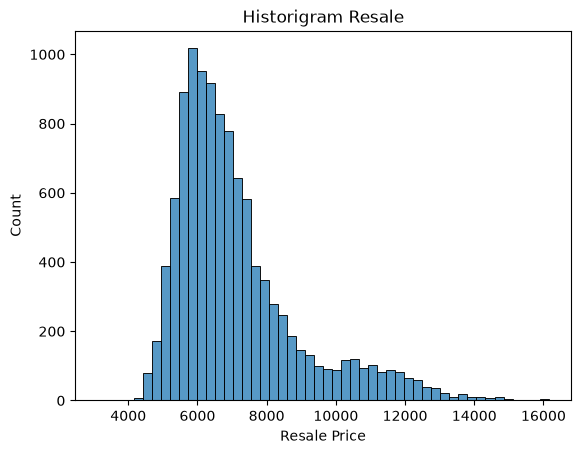

In [211]:
plt.Figure(figsize=(10,12))
sns.histplot(data=df_2025 , x='price_per_sqm',bins=50)
plt.title("Historigram Resale")
plt.xlabel("Resale Price")
plt.ylabel("Count")
plt.show()

In [ ]:
jurong_west = df_2025[(df_2025['town']=='JURONG WEST')]['price_per_sqm']

queenstown = df_2025[df_2025['town']=='QUEENSTOWN']['price_per_sqm']


dat = pd.DataFrame({
    'JURONGWEST' : jurong_west.shape,
    'QUEENSTOWN' : queenstown.shape,
    'Median_JURONG' : jurong_west.median(),
    'Median_QUEENS' : queenstown.median()
})


dat

,JURONGWEST,QUEENSTOWN,Median_JURONG,median_QUEENS
0,609,250,"5,631.07","10,783.95"


$H_0$ :  harga per m² flat 4 ROOM di Jurong West dan Queenstown (2025) tidak berbeda

$H_1$ :  harga per m² keduanya berbeda.

Tebakan Hipotesis = $H_1$ dilihat dari tabel di atas JURONGWEST punya total transaksi yang lebih banyak di tahun 2025 tapi punya median harga per m² di angka 5rb masih kalah dengan QUEENSTOWN yang punya 250 transaksi tapi punya median harga per m² 10rb

In [ ]:


mannwhitneyu(jurong_west,queenstown)

MannwhitneyuResult(statistic=np.float64(3079.0), pvalue=np.float64(2.342965320728006e-108))

Dari hasil ujicoba statistik Mann-Whitney, pvalue < 0.05 yang menandakan bahawa menolak $H_0$ dan menerima $H_1$

In [222]:
selisih = ((queenstown.median()- jurong_west.median()) / jurong_west.median())*100
print(f'Selisih {selisih:.2f}%')

Selisih 91.51%


dengan tipe flat (4 ROOM) dan tahun (2025) dikunci, median harga per m² Queenstown sekitar 91,5% di atas Jurong West, dan perbedaannya signifikan secara statistik. Artinya lokasi punya pengaruh nyata dan besar terhadap harga, bukan sekadar kebetulan.

In [228]:
df_2025.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,month_date,remaining_lease_year,is_duplicate,price_per_sqm,year,percentage_difference,is_outlier,lease_group
197534,2025-01,ANG MO KIO,4 ROOM,337,ANG MO KIO AVE 1,13 TO 15,91.00,New Generation,1982,56 years 03 months,"582,000.00",2025-01-01,56.25,False,"6,395.60",2025,0.42,False,50-60
197535,2025-01,ANG MO KIO,4 ROOM,310C,ANG MO KIO AVE 1,10 TO 12,94.00,Model A,2012,86 years 09 months,"865,000.00",2025-01-01,86.75,False,"9,202.13",2025,44.49,True,80-90
197536,2025-01,ANG MO KIO,4 ROOM,337,ANG MO KIO AVE 1,10 TO 12,91.00,New Generation,1982,56 years 02 months,"530,000.00",2025-01-01,56.17,False,"5,824.18",2025,-8.55,False,50-60
197537,2025-02,ANG MO KIO,4 ROOM,226,ANG MO KIO AVE 1,07 TO 09,91.00,New Generation,1978,52 years,"560,000.00",2025-02-01,52.00,False,"6,153.85",2025,-3.37,False,50-60
197538,2025-02,ANG MO KIO,4 ROOM,310C,ANG MO KIO AVE 1,28 TO 30,96.00,Model A,2012,86 years 08 months,"1,038,000.00",2025-02-01,86.67,False,"10,812.50",2025,69.78,True,80-90


In [227]:
df_2025.shape

(10843, 19)

# Data Preparation

In [234]:
df_numeric = df.select_dtypes(include='number')

pd.options.display.float_format = "{:,.2f}".format

corr_matrix = df_numeric.corr()
corr_matrix

,floor_area_sqm,lease_commence_date,resale_price,remaining_lease_year,price_per_sqm,year,percentage_difference
floor_area_sqm,1.00,0.09,0.56,0.10,-0.15,-0.04,-0.11
lease_commence_date,0.09,1.00,0.38,0.98,0.42,0.13,0.47
resale_price,0.56,0.38,1.00,0.30,0.71,0.42,0.37
remaining_lease_year,0.10,0.98,0.30,1.00,0.32,-0.06,0.47
price_per_sqm,-0.15,0.42,0.71,0.32,1.00,0.54,0.57
year,-0.04,0.13,0.42,-0.06,0.54,1.00,0.02
percentage_difference,-0.11,0.47,0.37,0.47,0.57,0.02,1.00


<Axes: >

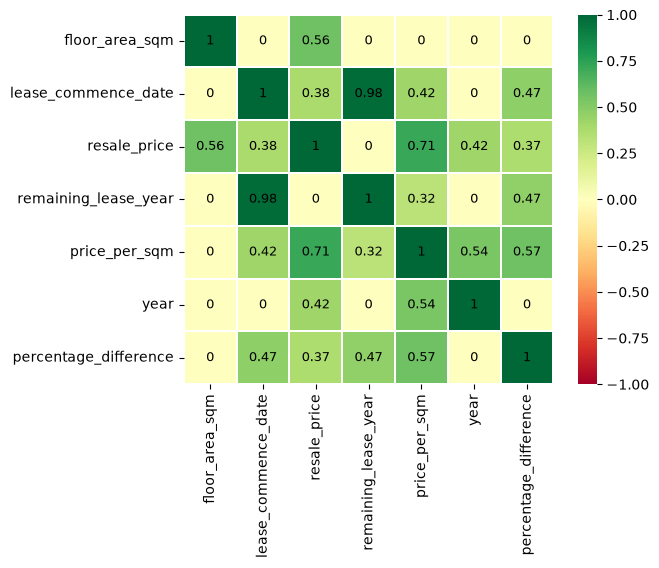

In [ ]:


corr_matrix[(corr_matrix< 0.3) & (corr_matrix>-0.3)] = 0

mask=np.triu(np.ones_like(corr_matrix,dtype=bool))

cmap= "RdYlGn"

sns.heatmap(
    data=corr_matrix,
    vmax=1.0,vmin=-1.0, linewidths=0.1, 
    annot_kws={
        "size": 9,
        "color": "black"
    },
    square=True,
    cmap=cmap,
    annot=True
)

In [237]:
cor_with_resale_price = df_numeric.corr()['resale_price'].drop('resale_price')

strong_cor = (
    cor_with_resale_price[abs(cor_with_resale_price)>=0.5]
    .sort_values(ascending=False)
)


modderate_cor = (
    cor_with_resale_price[(abs(cor_with_resale_price)<=0.5) & (abs(cor_with_resale_price)>0.2)]
    .sort_values(ascending=False)
)

print(strong_cor)
print("================================")
print(modderate_cor)

price_per_sqm    0.71
floor_area_sqm   0.56
Name: resale_price, dtype: float64
year                    0.42
lease_commence_date     0.38
percentage_difference   0.37
remaining_lease_year    0.30
Name: resale_price, dtype: float64


In [241]:
df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,month_date,remaining_lease_year,is_duplicate,price_per_sqm,year,percentage_difference,is_outlier
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.00,Improved,1979,61 years 04 months,"232,000.00",2017-01-01,61.33,False,"5,272.73",2017,0.00,False
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.00,New Generation,1978,60 years 07 months,"250,000.00",2017-01-01,60.58,False,"3,731.34",2017,-15.14,False
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.00,New Generation,1980,62 years 05 months,"262,000.00",2017-01-01,62.42,False,"3,910.45",2017,-11.07,False
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.00,New Generation,1980,62 years 01 month,"265,000.00",2017-01-01,62.08,False,"3,897.06",2017,-11.38,False
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.00,New Generation,1980,62 years 05 months,"265,000.00",2017-01-01,62.42,False,"3,955.22",2017,-10.05,False


In [312]:
feature = ['town','flat_type','floor_area_sqm','flat_model','lease_commence_date','month_date','remaining_lease_year','resale_price','storey_range']

df_model = df.loc[:,feature]

df_model

,town,flat_type,floor_area_sqm,flat_model,lease_commence_date,month_date,remaining_lease_year,resale_price,storey_range
0,ANG MO KIO,2 ROOM,44.00,Improved,1979,2017-01-01,61.33,"232,000.00",10 TO 12
1,ANG MO KIO,3 ROOM,67.00,New Generation,1978,2017-01-01,60.58,"250,000.00",01 TO 03
2,ANG MO KIO,3 ROOM,67.00,New Generation,1980,2017-01-01,62.42,"262,000.00",01 TO 03
3,ANG MO KIO,3 ROOM,68.00,New Generation,1980,2017-01-01,62.08,"265,000.00",04 TO 06
4,ANG MO KIO,3 ROOM,67.00,New Generation,1980,2017-01-01,62.42,"265,000.00",01 TO 03
...,...,...,...,...,...,...,...,...,...
242139,YISHUN,EXECUTIVE,146.00,Maisonette,1988,2026-09-01,60.42,"1,010,000.00",10 TO 12
242140,YISHUN,MULTI-GENERATION,164.00,Multi Generation,1987,2026-05-01,60.67,"1,120,000.00",04 TO 06
242141,YISHUN,MULTI-GENERATION,151.00,Multi Generation,1987,2026-09-01,60.33,"1,212,000.00",10 TO 12
242142,YISHUN,MULTI-GENERATION,163.00,Multi Generation,1988,2026-07-01,60.58,"1,190,000.00",07 TO 09


In [313]:
df_model['month_date']= pd.to_datetime(df_model['month_date'])
df_model['month_date'].describe()

count                        242144
mean     2022-01-25 20:40:52.134267
min             2017-01-01 00:00:00
25%             2019-11-01 00:00:00
50%             2022-03-01 00:00:00
75%             2024-06-01 00:00:00
max             2026-10-01 00:00:00
Name: month_date, dtype: object

In [314]:
df_model['month_since_start'] = ((df_model['month_date'].dt.year - df_model['month_date'].dt.year.min())*12) + (df_model['month_date'].dt.month - df_model['month_date'].dt.month.min())

In [315]:
df_model[(df_model['month_date'].dt.month < 10) & (df_model['month_date'].dt.year < 2026)].copy()



,town,flat_type,floor_area_sqm,flat_model,lease_commence_date,month_date,remaining_lease_year,resale_price,storey_range,month_since_start
0,ANG MO KIO,2 ROOM,44.00,Improved,1979,2017-01-01,61.33,"232,000.00",10 TO 12,0
1,ANG MO KIO,3 ROOM,67.00,New Generation,1978,2017-01-01,60.58,"250,000.00",01 TO 03,0
2,ANG MO KIO,3 ROOM,67.00,New Generation,1980,2017-01-01,62.42,"262,000.00",01 TO 03,0
3,ANG MO KIO,3 ROOM,68.00,New Generation,1980,2017-01-01,62.08,"265,000.00",04 TO 06,0
4,ANG MO KIO,3 ROOM,67.00,New Generation,1980,2017-01-01,62.42,"265,000.00",01 TO 03,0
...,...,...,...,...,...,...,...,...,...,...
222061,YISHUN,EXECUTIVE,146.00,Maisonette,1987,2025-07-01,61.42,"980,000.00",04 TO 06,102
222062,YISHUN,EXECUTIVE,145.00,Maisonette,1987,2025-09-01,61.25,"980,000.00",10 TO 12,104
222063,YISHUN,EXECUTIVE,146.00,Maisonette,1988,2025-09-01,61.33,"990,000.00",04 TO 06,104
222065,YISHUN,MULTI-GENERATION,147.00,Multi Generation,1987,2025-05-01,61.50,"945,000.00",04 TO 06,100


In [316]:
df_model.describe()

,floor_area_sqm,lease_commence_date,month_date,remaining_lease_year,resale_price,month_since_start
count,"242,144.00","242,144.00",242144,"242,144.00","242,144.00","242,144.00"
mean,96.71,"1,996.63",2022-01-25 20:40:52.134267,74.06,"536,120.58",60.84
min,31.00,"1,966.00",2017-01-01 00:00:00,39.33,"140,000.00",0.00
25%,81.00,"1,985.00",2019-11-01 00:00:00,62.17,"392,000.00",34.00
50%,93.00,"1,997.00",2022-03-01 00:00:00,73.75,"505,000.00",62.00
75%,112.00,"2,012.00",2024-06-01 00:00:00,88.50,"645,000.00",89.00
max,366.70,"2,023.00",2026-10-01 00:00:00,97.75,"1,728,000.00",117.00
std,24.02,14.40,NaN,14.34,"193,204.78",32.79


In [317]:
# df_model_test = df_model[(df_model['month_date'].dt.year < 2026) & (df_model['month_date'].dt.month<=9)].copy()
# df_model_train = df_model[(df_model['month_date'].dt.year < 2026)].copy()
df_model_test = df_model[(df_model['month_date'].dt.year == 2026) & (df_model['month_date'].dt.month <= 9)].copy()
df_model_train = df_model[df_model['month_date'].dt.year < 2026].copy()

count_train_test_split = pd.DataFrame(
    {
        'Train_Count': df_model_train.shape,
        'Test_Count' : df_model_test.shape
    }
)
print(len(df_model_train), len(df_model_test))
count_train_test_split

222067 19639


,Train_Count,Test_Count
0,222067,19639
1,10,10


In [318]:



baseline = df_model_train.groupby('flat_type')['resale_price'].transform('median')

global_median = df_model_train['resale_price'].median()

median_per_type = df_model_train.groupby('flat_type')['resale_price'].median()
df_model_test['baseline_prediction'] = (df_model_test['flat_type'].map(median_per_type).fillna(global_median))


mae_baseline = mean_absolute_error(df_model_test['resale_price'],df_model_test['baseline_prediction'])

mape_baseline = mean_absolute_percentage_error(df_model_test['resale_price'],df_model_test['baseline_prediction'])

print(f'Baseline MAE: S$ {mae_baseline:,.2f}')
print(f'Baseline MAPE: {mape_baseline * 100:.2f}%')

Baseline MAE: S$ 170,218.60
Baseline MAPE: 22.23%


In [319]:
# 1. Untuk Data Train
train_extracted = df_model_train['storey_range'].str.extract(r'(\d+) TO (\d+)').astype(float)
df_model_train['storey_mid'] = (train_extracted[0] + train_extracted[1]) / 2

# 2. Untuk Data Test (Perhatikan: sumbernya harus df_model_test)
test_extracted = df_model_test['storey_range'].str.extract(r'(\d+) TO (\d+)').astype(float)
df_model_test['storey_mid'] = (test_extracted[0] + test_extracted[1]) / 2

In [321]:
cat_cols = ['town', 'flat_type', 'flat_model']
num_cols = ['floor_area_sqm', 'remaining_lease_year', 'storey_mid', 'month_since_start']

preprosesing = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'),cat_cols),
    ('num', 'passthrough', num_cols)
])


X_train= preprosesing.fit_transform(df_model_train[cat_cols+ num_cols])
X_test = preprosesing.transform(df_model_test[cat_cols + num_cols])
y_train = df_model_train['resale_price']
y_test  = df_model_test ['resale_price']



In [322]:
print(cat_cols)
print(num_cols)
print(X_train.shape, X_test.shape)

['town', 'flat_type', 'flat_model']
['floor_area_sqm', 'remaining_lease_year', 'storey_mid', 'month_since_start']
(222067, 58) (19639, 58)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_absolute_percentage_error

lr = LinearRegression()

lr.fit(X_train,y_train)
predict_lr = lr.predict(X_test)


mae_lr = mean_absolute_error(y_test,predict_lr)
mape_lr =mean_absolute_percentage_error(y_test,predict_lr)*100
print(f'Mean Absolute Error : {mae_lr:,.2f}')
print(f'Mean Absolute Precentage Error : {mape_lr:,.2f}%')

Mean Absolute Error : 63,848.51
Mean Absolute Precentage Error : 10.08 


In [394]:
def print_model_comparison (mae_reference_model,mae_model,model_name="Model Baru", reference_name= "Model Pembanding") :
    selisih_predict = ((mae_model - mae_reference_model)/mae_reference_model)*100
    
    print(f'MAE {model_name} : {mae_model:,.2f}')
    print(f'MAE {reference_name} : {mae_reference_model:,.2f}')
    
    
    if selisih_predict>0:
        print(f'Kenaikan error dari baseline sebesar {selisih_predict:,.2f}% ({model_name} lebih jelek dari {reference_name}\n')
    else:
        print(f'Penurunan error dari baseline sebesar {abs(selisih_predict):,.2f}% {model_name} lebih baik dari {reference_name}\n')
    
    
    
    
def print_mape_model_comparison (mape_reference_model, mape_model, reference_name = "Model pembanding", model_name="Model") :
    selisih_predict = (mape_model - mape_reference_model)
    
    print(f'MAPE {model_name} : {mape_model:,.2f}%')
    print(f'MA_E {reference_name} : {mape_reference_model:,.2f}%')
    
    if selisih_predict>0:
        print(f'Kenaikan error dari baseline sebesar {selisih_predict:,.2f}% ({model_name} lebih jelek dari {reference_name}\n')
    else:
        print(f'Penurunan error dari baseline sebesar {abs(selisih_predict):,.2f}% {model_name} lebih baik dari {reference_name}\n')
    

In [343]:
print_model_comparison(mae_baseline,mae_lr,"LinearRegression","Baseline")

MAE LinearRegression : 63,848.51
MAE Baseline : 170,218.60
Penurunan error dari baseline sebesar 62.49% LinearRegression lebih baik dari Baseline)



In [350]:
df_model_test['pred_lr'] = predict_lr
df_model_test['error'] = df_model_test['resale_price'] - df_model_test['pred_lr'] 
df_model_test['ape'] = df_model_test['error'].abs()/ df_model_test['resale_price']*100



In [355]:
df_model_test['error'].mean().round()

np.float64(-3699.0)

In [352]:
df_model_test.groupby('town')['ape'].mean().sort_values()

town
TAMPINES           5.12
PASIR RIS          5.47
WOODLANDS          6.07
CHOA CHU KANG      6.38
PUNGGOL            6.45
SEMBAWANG          6.59
SENGKANG           6.77
HOUGANG            7.83
BUKIT PANJANG      8.44
YISHUN             8.99
BUKIT BATOK        9.28
JURONG WEST        9.42
SERANGOON         10.55
BISHAN            11.00
JURONG EAST       11.34
BEDOK             11.98
CENTRAL AREA      12.16
BUKIT TIMAH       14.08
KALLANG/WHAMPOA   15.62
ANG MO KIO        15.73
GEYLANG           16.81
MARINE PARADE     17.86
CLEMENTI          18.28
QUEENSTOWN        19.05
BUKIT MERAH       19.63
TOA PAYOH         19.95
Name: ape, dtype: float64

In [353]:
df_model_test.groupby('flat_type')['ape'].mean().sort_values()

flat_type
EXECUTIVE           7.81
4 ROOM              8.34
5 ROOM              8.36
2 ROOM             14.83
3 ROOM             15.15
MULTI-GENERATION   15.22
1 ROOM             34.84
Name: ape, dtype: float64

In [354]:
df_model_test.groupby('flat_model')['ape'].mean().sort_values()

flat_model
Model A2                  6.06
Terrace                   6.35
3Gen                      7.33
Apartment                 7.36
Model A                   8.03
Simplified                8.33
Maisonette                8.68
Premium Apartment         8.99
Premium Maisonette        9.71
Type S1                   9.90
DBSS                     10.10
Improved-Maisonette      10.20
2-room                   10.88
Model A-Maisonette       11.17
Improved                 11.86
Adjoined flat            12.29
New Generation           13.46
Premium Apartment Loft   13.81
Multi Generation         15.22
Type S2                  17.39
Standard                 25.60
Name: ape, dtype: float64

**Secara keseluruhan, model Linear Regression ini sudah bekerja dengan cukup baik sebagai fondasi awal. Namun, performanya terbelah menjadi dua: sangat akurat di wilayah pinggiran/standar, tetapi gagal total di kawasan elit/matang dan tipe unit ekstrem.**

Linear Regression kesulitan menangkap interaksi antar fitur, dan di situlah error terbesar. Model berbasis pohon (tree-based) mampu menangkap interaksi itu tanpa kita menuliskannya.

In [364]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgbr = HistGradientBoostingRegressor(random_state=42)
hgbr.fit(X_train.toarray(),y_train)
pred_hgbr = hgbr.predict(X_test.toarray())


mae_hgbr = mean_absolute_error(pred_hgbr,y_test)
mape_hgbr= mean_absolute_percentage_error(pred_hgbr,y_test)*100

print_model_comparison(mae_hgbr,mae_lr,"LinearRegression","HistGradientBoostingRegressor")

print_model_comparison(mae_baseline,mae_hgbr,"HistGradientBoostingRegressor","Baseline")

MAE LinearRegression : 63,848.51
MAE HistGradientBoostingRegressor : 43,592.82
Kenaikan error dari baseline sebesar 46.47% (LinearRegression lebih jelek dari HistGradientBoostingRegressor)

MAE HistGradientBoostingRegressor : 43,592.82
MAE Baseline : 170,218.60
Penurunan error dari baseline sebesar 74.39% HistGradientBoostingRegressor lebih baik dari Baseline)



In [ ]:
df_model_test['pred_hgbr'] = pred_hgbr
df_model_test['error']= df_model_test['pred_hgbr'] - df_model_test['resale_price']
df_model_test['ape_hgbr'] = df_model_test['error'].abs() / df_model_test['resale_price']*100


df_model_test.groupby('town')['ape_hgbr'].mean().sort_values()




,town_erorr_ape,town_error_ape_hgbr,difference
town,,,
ANG MO KIO,15.73,6.71,134.43
BEDOK,11.98,6.69,79.04
BISHAN,11.00,6.69,64.43
BUKIT BATOK,9.28,5.32,74.30
BUKIT MERAH,19.63,9.75,101.39
BUKIT PANJANG,8.44,8.12,3.91
BUKIT TIMAH,14.08,6.91,103.75
CENTRAL AREA,12.16,10.80,12.66
CHOA CHU KANG,6.38,5.31,20.09


In [380]:
dtf = pd.DataFrame({
    'ape_lr': df_model_test.groupby('town')['ape'].mean(),
    'ape_hgb': df_model_test.groupby('town')['ape_hgbr'].mean()
})

dtf['difference'] = (dtf['ape_hgb']- dtf['ape_lr']) 

dtf = dtf.sort_values(by='ape_lr', ascending=False)

print(dtf)

                 ape_lr  ape_hgb  difference
town                                        
TOA PAYOH         19.95     9.05      -10.91
BUKIT MERAH       19.63     9.75       -9.88
QUEENSTOWN        19.05     8.03      -11.02
CLEMENTI          18.28     7.92      -10.36
MARINE PARADE     17.86     8.39       -9.47
GEYLANG           16.81     8.06       -8.75
ANG MO KIO        15.73     6.71       -9.02
KALLANG/WHAMPOA   15.62     8.78       -6.83
BUKIT TIMAH       14.08     6.91       -7.17
CENTRAL AREA      12.16    10.80       -1.37
BEDOK             11.98     6.69       -5.29
JURONG EAST       11.34     7.02       -4.33
BISHAN            11.00     6.69       -4.31
SERANGOON         10.55     8.76       -1.78
JURONG WEST        9.42     6.73       -2.69
BUKIT BATOK        9.28     5.32       -3.95
YISHUN             8.99     5.85       -3.14
BUKIT PANJANG      8.44     8.12       -0.32
HOUGANG            7.83     5.81       -2.02
SENGKANG           6.77     6.30       -0.46
SEMBAWANG 

**Dengan menggunakan HistGradientBostingRegresion model lebih bisa menebak pola yang tidak bisa di tebak oleh linear regresion. Jadinya hasilnya bisa dilihat dari data di atas HistGradientBoostingRegreseion mengalami penurunan error sebesar 46.4% dan jika di kelompokan per wilayah kota hasil errornya juga lebih merata ke seluruh kota tidak seperti linear Regression**

# Cek The Most Importance Feature

In [386]:
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance


cat_cols = ['town', 'flat_type', 'flat_model']
num_cols = ['floor_area_sqm', 'remaining_lease_year', 'storey_mid', 'month_since_start']

preprosesing2 = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_cols ),
    ('num', 'passthrough', num_cols)
])


model = Pipeline([
    ('pre', preprosesing2), 
    ('hgbr', HistGradientBoostingRegressor(random_state=42))
])

model.fit(df_model_train[cat_cols+num_cols],y_train)


result = permutation_importance (model, df_model_test[cat_cols+num_cols],y_test,scoring='neg_mean_absolute_error', n_repeats=5, random_state=42)

imp = pd.Series(result.importances_mean, index=cat_cols + num_cols).sort_values(ascending=False)

print(imp)

floor_area_sqm         108,627.19
town                    67,508.47
remaining_lease_year    55,154.12
storey_mid              14,041.99
flat_type               13,207.23
flat_model               5,016.76
month_since_start            0.00
dtype: float64


In [395]:
print_mape_model_comparison(mape_lr,mape_hgbr,'LinearRegression', 'HistGradientBoostingRegressor')

MAPE HistGradientBoostingRegressor : 6.44%
MA_E LinearRegression : 10.08%
Penurunan error dari baseline sebesar 3.64% HistGradientBoostingRegressor lebih baik dari LinearRegression



In [396]:
print(df_model_train['month_since_start'].describe())
print(df_model_test['month_since_start'].describe())
print(df_model_train['month_since_start'].nunique())

count   222,067.00
mean         56.19
std          30.18
min           0.00
25%          31.00
50%          57.00
75%          82.00
max         107.00
Name: month_since_start, dtype: float64
count   19,639.00
mean       112.18
std          2.60
min        108.00
25%        110.00
50%        112.00
75%        114.00
max        116.00
Name: month_since_start, dtype: float64
108


In [397]:
train_a = df_model_train[df_model_train['month_date'].dt.year < 2025]
val_a   = df_model_train[df_model_train['month_date'].dt.year == 2025]

feats_with    = cat_cols + num_cols                      # dengan waktu
feats_without = [c for c in feats_with if c != 'month_since_start']   # tanpa waktu

for nama, feats in [('dengan waktu', feats_with), ('tanpa waktu', feats_without)]:
    pre_x = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         [c for c in feats if c in cat_cols]),
        ('num', 'passthrough', [c for c in feats if c in num_cols]),
    ])
    m = Pipeline([('pre', pre_x), ('hgb', HistGradientBoostingRegressor(random_state=42))])
    m.fit(train_a[feats], train_a['resale_price'])
    p = m.predict(val_a[feats])
    print(nama, mean_absolute_error(val_a['resale_price'], p))

dengan waktu 43150.21967773547
tanpa waktu 114789.07877648801


In [398]:
def eval_feats(feats):
    c = [x for x in feats if x in cat_cols]
    n = [x for x in feats if x in num_cols]
    pre_x = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), c),
        ('num', 'passthrough', n),
    ])
    m = Pipeline([('pre', pre_x), ('hgb', HistGradientBoostingRegressor(random_state=42))])
    m.fit(train_a[feats], train_a['resale_price'])
    return mean_absolute_error(val_a['resale_price'], m.predict(val_a[feats]))

all_feats = cat_cols + num_cols
base_mae = eval_feats(all_feats)

hasil = {}
for f in all_feats:
    hasil[f] = eval_feats([x for x in all_feats if x != f]) - base_mae

print(pd.Series(hasil).sort_values(ascending=False))

month_since_start      71,638.86
town                   27,131.45
remaining_lease_year    6,321.29
storey_mid              3,490.32
floor_area_sqm          2,235.17
flat_model                573.88
flat_type                 265.09
dtype: float64


In [401]:

from sklearn.compose import TransformedTargetRegressor

fitur = cat_cols + num_cols

model_log = TransformedTargetRegressor(
    regressor=Pipeline([('pre', preprosesing2),
                        ('hgb', HistGradientBoostingRegressor(random_state=42))]),
    func=np.log1p,
    inverse_func=np.expm1,
)
model_log.fit(df_model_train[fitur], y_train)
pred_log = model_log.predict(df_model_test[fitur])

print(f'MAE : {mean_absolute_error(y_test, pred_log)}')
print(f'MAPE : {mean_absolute_percentage_error(y_test, pred_log) * 100}')

MAE : 45540.53311348426
MAPE : 6.572406508049279


In [402]:
df_model_test['pred_final'] = model.predict(df_model_test[cat_cols + num_cols])
df_model_test['err_final'] = df_model_test['resale_price'] - df_model_test['pred_final']
df_model_test['ape_final'] = df_model_test['err_final'].abs() / df_model_test['resale_price'] * 100

# 1. Error per bulan 2026
print(df_model_test.groupby(df_model_test['month_date'].dt.month)[['err_final', 'ape_final']].mean())

# 2. Seberapa sering tebakan cukup dekat?
for t in [5, 10, 20]:
    print(f'Dalam {t}%:', (df_model_test['ape_final'] <= t).mean() * 100)

            err_final  ape_final
month_date                      
1            1,816.16       5.94
2              881.08       6.33
3            2,524.82       6.39
4             -357.52       6.15
5            1,095.02       6.66
6              661.47       6.46
7           -1,703.06       6.55
8             -297.66       6.73
9            3,097.48       6.98
Dalam 5%: 49.08600234227812
Dalam 10%: 78.552879474515
Dalam 20%: 97.42349406792606
